# Análise de ROI em Publicidade — Melhores Compras
**PBL Fase 5 · Terceiro desafio** — Regressão linear entre gastos com publicidade por mídia e a previsão de aumento de vendas.

**Grupo Paladinos · Turma 2TSCOA:** Igor Cardoso Soares da Silva (RM 566173) · Murilo Jucá de Carvalho (RM 562692) · Rozana da Malta Martins (RM 561821) · Ruan Duarte Garcia (RM 566167)

**Como reproduzir:** manter `../data/gastos_publicidade.csv` na mesma pasta do notebook e executar *Run All*. Requer pandas, numpy, matplotlib, seaborn e scikit-learn.

**Objetivo:** construir o modelo de regressão com o **maior R²** possível (sem overfitting), gerar a matriz de correlação,
os gráficos de dispersão e uma análise explicativa para o time de Marketing indicando quais mídias trazem o melhor ROI.

> O arquivo `../data/gastos_publicidade.csv` **não é alterado**. Todas as transformações são feitas em memória, neste notebook.

## 1. Bibliotecas e configuração

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
import sklearn
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
pd.set_option('display.width', 160)
SEED = 42

# Paleta e estilo (tinta neutra, grade discreta)
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#898781'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'text.color': '#0b0b0b', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'font.size': 10,
})
print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__, '| seaborn', sns.__version__)

pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.1 | seaborn 0.13.2


## 2. Carga dos dados (arquivo original, somente leitura)

In [2]:
ARQ = '../data/gastos_publicidade.csv'
caminho = next(p for p in [Path(ARQ), Path('dados') / ARQ, Path('..') / 'dados' / '3o_Desafio' / ARQ] if p.exists())
bruto = pd.read_csv(caminho)
print('Arquivo:', caminho, '| formato:', bruto.shape)
bruto.head(10)

Arquivo: ../data/gastos_publicidade.csv | formato: (200, 5)


,Ano,Mes,Tipo de Midia,Gastos com Publicidade (em R$),Previsao Inicial de Aumento de Vendas (em mil unidades)
0,2022,1,Paginas web,87000,1000
1,2022,1,Redes sociais,120000,800
2,2022,1,TV,250000,1500
3,2022,1,Jornal,110000,730
4,2022,1,Revista,40000,360
5,2022,1,Radio,75000,450
6,2022,2,Paginas web,80000,980
7,2022,2,Redes sociais,110000,750
8,2022,2,TV,200000,1300
9,2022,2,Jornal,90000,700


In [3]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                                                   Non-Null Count  Dtype
---  ------                                                   --------------  -----
 0   Ano                                                      200 non-null    int64
 1   Mes                                                      200 non-null    int64
 2   Tipo de Midia                                            200 non-null    str  
 3   Gastos com Publicidade (em R$)                           200 non-null    str  
 4   Previsao Inicial de Aumento de Vendas (em mil unidades)  200 non-null    int64
dtypes: int64(3), str(2)
memory usage: 7.9 KB


## 3. Qualidade e tratamento dos dados
A coluna de gastos foi lida como texto (`object`), indicando valores fora do padrão numérico. Vamos localizá-los antes de converter.

In [4]:
col_gasto = 'Gastos com Publicidade (em R$)'
nao_numericos = bruto[pd.to_numeric(bruto[col_gasto], errors='coerce').isna()]
print('Valores de gasto não numéricos:')
nao_numericos

Valores de gasto não numéricos:


,Ano,Mes,Tipo de Midia,Gastos com Publicidade (em R$),Previsao Inicial de Aumento de Vendas (em mil unidades)
146,2024,1,Paginas web,"99388,8",1190
189,2024,6,Jornal,"142105,6",1044
191,2024,6,Radio,"103286,4",824


In [5]:
df = bruto.rename(columns={
    'Ano': 'ano', 'Mes': 'mes', 'Tipo de Midia': 'midia',
    'Gastos com Publicidade (em R$)': 'gasto',
    'Previsao Inicial de Aumento de Vendas (em mil unidades)': 'vendas',
}).copy()

# Os 3 valores usam vírgula como separador decimal (padrão brasileiro): '99388,8' -> 99388.8
df['gasto'] = df['gasto'].astype(str).str.replace(',', '.', regex=False).astype(float)
df['vendas'] = df['vendas'].astype(float)
df['midia'] = df['midia'].str.strip()

print('Nulos por coluna:', df.isna().sum().to_dict())
print('Linhas duplicadas:', df.duplicated().sum())
df.describe()

Nulos por coluna: {'ano': 0, 'mes': 0, 'midia': 0, 'gasto': 0, 'vendas': 0}
Linhas duplicadas: 0


,ano,mes,gasto,vendas
count,200.0000,200.0000,200.0000,200.0000
mean,"2,022.9200",5.8100,"156,151.3140","1,655.3600"
std,0.7980,3.3270,"75,946.1084","1,106.9722"
min,"2,022.0000",1.0000,"11,000.0000",200.0000
25%,"2,022.0000",3.0000,"100,800.0000",822.0000
50%,"2,023.0000",5.5000,"139,550.0000","1,400.0000"
75%,"2,024.0000",8.2500,"203,700.0000","2,132.0000"
max,"2,024.0000",12.0000,"335,664.0000","5,310.0000"


In [6]:
# Quantidade de registros por mídia e ano: Instagram e Google só existem em 2024
pd.crosstab(df['midia'], df['ano'], margins=True, margins_name='Total')

ano,2022,2023,2024,Total
midia,,,,
Google,0,0,7,7
Instagram,0,0,7,7
Jornal,12,12,7,31
Paginas web,12,12,7,31
Radio,12,12,7,31
Redes sociais,12,12,7,31
Revista,12,12,7,31
TV,12,12,7,31
Total,72,72,56,200


In [7]:
resumo = df.groupby('midia').agg(meses=('vendas', 'size'), gasto_medio=('gasto', 'mean'),
                                 vendas_medias=('vendas', 'mean'))
resumo['vendas_por_R$1000'] = (df['vendas'] / df['gasto']).groupby(df['midia']).mean() * 1000
resumo.sort_values('vendas_por_R$1000', ascending=False)

,meses,gasto_medio,vendas_medias,vendas_por_R$1000
midia,,,,
Google,7,"139,285.7143","4,500.0000",32.3077
Instagram,7,"179,614.2857","4,898.5714",27.2727
Paginas web,31,"152,042.9935","1,983.4194",13.1104
Revista,31,"81,141.1613",833.0000,10.2416
Radio,31,"96,909.8839",884.0000,9.4086
Redes sociais,31,"195,459.0968","1,721.2581",8.5354
Jornal,31,"143,672.3097","1,219.1290",8.1861
TV,31,"266,192.7097","1,916.6774",7.1426


### Comentários — qualidade dos dados
* A base tem **200 linhas e 5 colunas**, sem nulos e sem duplicidades.
* **3 valores de gasto** estavam com vírgula decimal (`99388,8` em Páginas web jan/2024, `142105,6` em Jornal jun/2024 e `103286,4` em Rádio jun/2024). Se não forem tratados, a coluna inteira vira texto e a regressão não roda. A conversão é feita só em memória.
* **Instagram e Google existem apenas em 2024** (7 meses, jan–jul). As outras 6 mídias têm 31 meses (2022, 2023 e jan–jul/2024). Qualquer conclusão sobre essas duas novas mídias se apoia em **poucos pontos**.
* Uma leitura inicial do retorno médio (vendas ÷ gasto) já mostra a diferença entre os canais: Google (32,3 mil unidades por R$ 1.000) e Instagram (27,3) ficam muito à frente de Páginas web (13,1), e a TV fica em último (7,1).
* Atenção de negócio: a variável-alvo é a **"Previsão Inicial de Aumento de Vendas"**, uma estimativa, e não a venda realizada. O modelo, portanto, explica essa previsão.

## 4. Preparação das variáveis (dicas *a* e *b* do enunciado)
* **Dica a — variável dummy:** `midia` é categórica e não entra diretamente na regressão. Criamos uma coluna 0/1 por mídia.
* **Dica b — gasto por mídia:** a coluna `gasto` mistura o investimento de todas as mídias. Usá-la sozinha força **uma única inclinação** para todos os canais.
  Por isso criamos `gasto_<mídia>` = gasto × dummy — o valor investido naquela mídia (zero nas demais linhas). Assim, cada canal ganha a própria inclinação, que é exatamente o **retorno marginal** do canal.

In [8]:
dummies = pd.get_dummies(df['midia'], prefix='is', dtype=float)
gastos_midia = dummies.mul(df['gasto'], axis=0)
gastos_midia.columns = [c.replace('is_', 'gasto_') for c in dummies.columns]

base = pd.concat([df[['ano', 'mes', 'gasto', 'vendas']], dummies, gastos_midia], axis=1)
MIDIAS = sorted(df['midia'].unique())
base.head()

,ano,mes,gasto,vendas,is_Google,is_Instagram,is_Jornal,is_Paginas web,is_Radio,is_Redes sociais,is_Revista,is_TV,gasto_Google,gasto_Instagram,gasto_Jornal,gasto_Paginas web,gasto_Radio,gasto_Redes sociais,gasto_Revista,gasto_TV
0,2022,1,"87,000.0000","1,000.0000",0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"87,000.0000",0.0000,0.0000,0.0000,0.0000
1,2022,1,"120,000.0000",800.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"120,000.0000",0.0000,0.0000
2,2022,1,"250,000.0000","1,500.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"250,000.0000"
3,2022,1,"110,000.0000",730.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"110,000.0000",0.0000,0.0000,0.0000,0.0000,0.0000
4,2022,1,"40,000.0000",360.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"40,000.0000",0.0000


## 5. Matriz de correlação

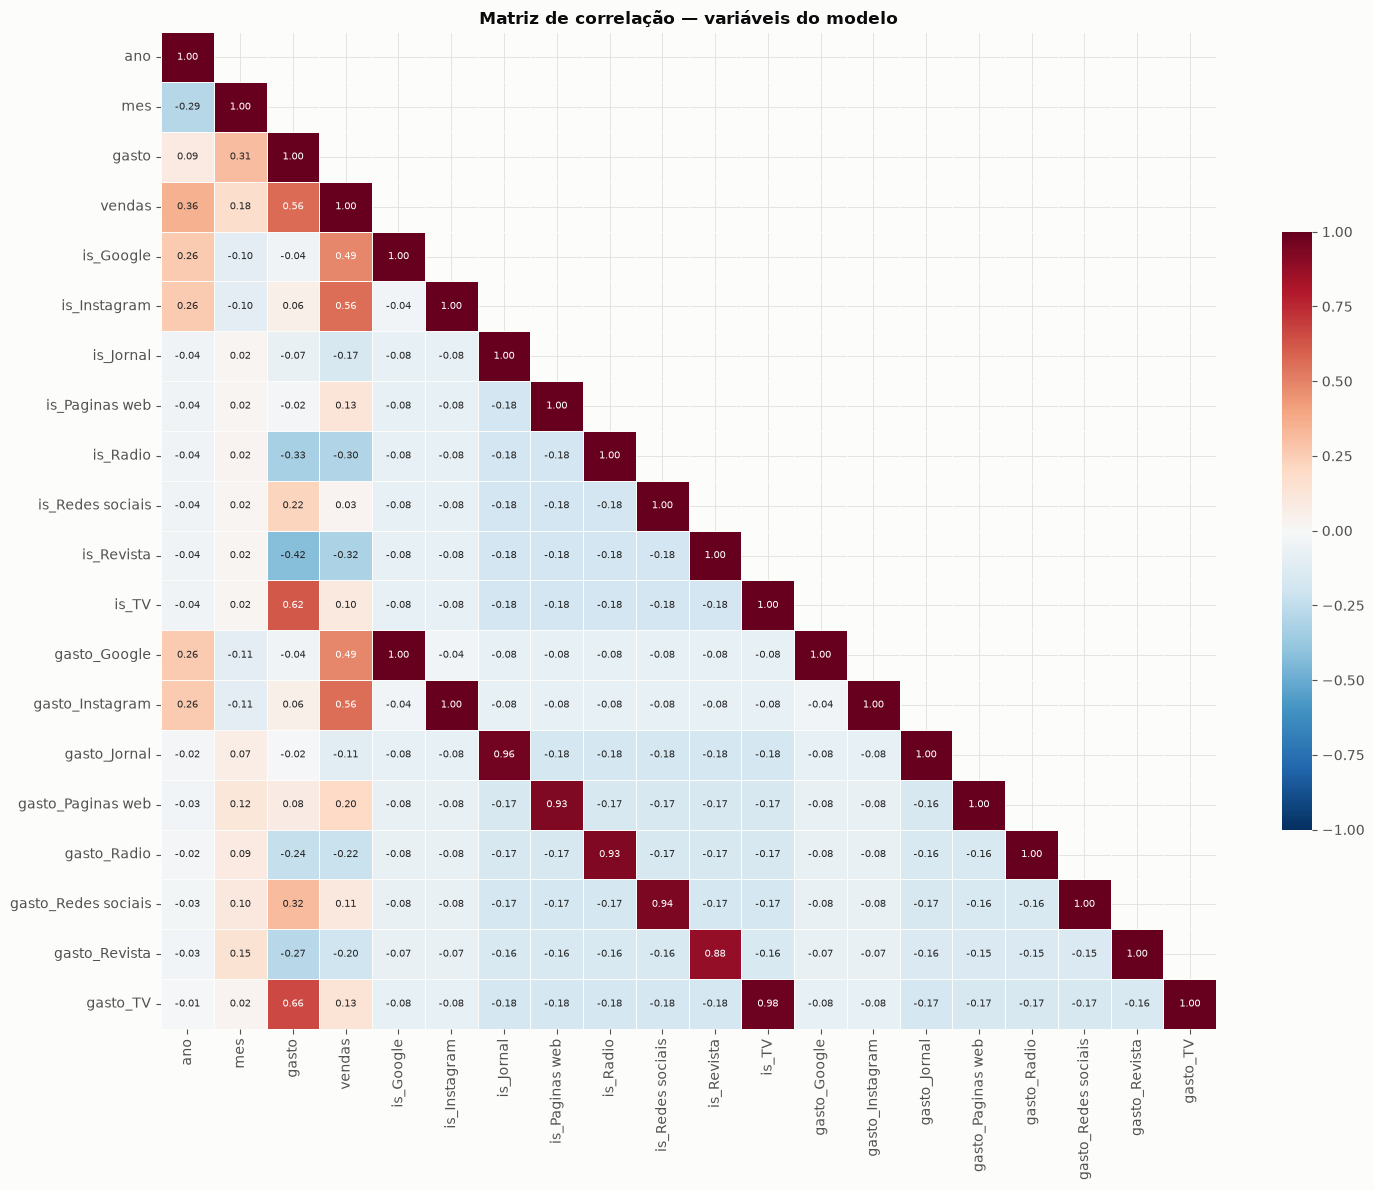

In [9]:
corr = base.corr()
fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='#fcfcfb', annot_kws={'size': 7}, cbar_kws={'shrink': 0.6}, ax=ax)
ax.set_title('Matriz de correlação — variáveis do modelo')
plt.tight_layout(); plt.show()

In [10]:
# Correlação de cada variável com a variável de interesse (vendas), em ordem
corr['vendas'].drop('vendas').sort_values(ascending=False).to_frame('correlação com vendas')

,correlação com vendas
gasto,0.5647
gasto_Instagram,0.5603
is_Instagram,0.5594
gasto_Google,0.4911
is_Google,0.4906
ano,0.3555
gasto_Paginas web,0.2021
mes,0.1766
gasto_TV,0.1333
is_Paginas web,0.1272


In [11]:
# Dentro de cada mídia: correlação entre o gasto na mídia e o aumento de vendas
corr_midia = pd.Series({m: g['gasto'].corr(g['vendas']) for m, g in df.groupby('midia')})
corr_midia.sort_values(ascending=False).to_frame('corr(gasto, vendas) dentro da mídia')

,"corr(gasto, vendas) dentro da mídia"
Google,1.0000
Instagram,1.0000
Revista,0.9798
Redes sociais,0.9774
Radio,0.9386
Jornal,0.9191
Paginas web,0.9185
TV,0.8593


### Comentários — matriz de correlação
* **Gasto total × vendas = 0,56 (moderada).** Com a coluna de gasto sem tratamento, canais com retornos muito diferentes ficam misturados, e a relação parece mais fraca do que é.
* **Dentro de cada mídia, a correlação é forte:** Revista 0,98, Redes sociais 0,98, Rádio 0,94, Jornal 0,92, Páginas web 0,92 e TV 0,86 (Google e Instagram = 1,00). Separar o gasto por mídia (`gasto_<mídia>`) é o que revela a relação real — é a justificativa da **dica b**.
* **`is_Instagram` (0,56) e `is_Google` (0,49)** são as dummies mais correlacionadas com as vendas: meses dessas mídias têm aumento médio de 4,5–4,9 mil unidades, contra 0,8–2,0 mil nas demais. Isso mostra que o **tipo de mídia importa** (**dica a**).
* **`is_Revista` (−0,32) e `is_Rádio` (−0,30)** têm correlação negativa, porque são canais de orçamento menor e de incremento absoluto menor.
* **`ano` (0,36)** tem correlação positiva, em boa parte porque os canais digitais de alto retorno entraram em 2024. **`mes` (0,18)** tem correlação fraca.
* **Multicolinearidade:** cada `is_<mídia>` é quase igual ao seu `gasto_<mídia>` (0,88 a 1,00), e `is_TV` × `gasto` = 0,62, já que a TV tem o maior orçamento. Por isso, nos modelos, **uma dummy é retirada** (categoria de referência), e a estabilidade é conferida pela validação cruzada.

## 6. Gráficos de dispersão — cada variável independente × aumento de vendas

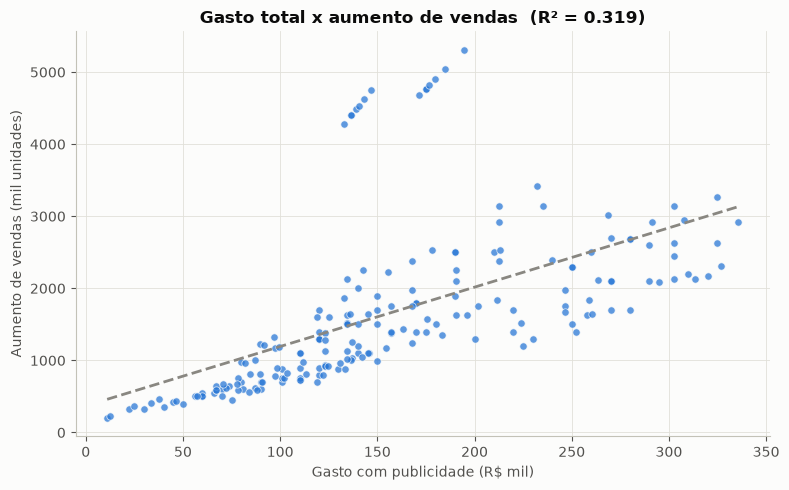

In [12]:
# 6.1 Gasto total (sem tratamento) x vendas: uma única nuvem mistura canais com retornos diferentes
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['gasto'] / 1000, df['vendas'], s=28, color=AZUL, alpha=0.75, edgecolor='#fcfcfb', linewidth=0.6)
m = LinearRegression().fit(df[['gasto']], df['vendas'])
xs = np.linspace(df['gasto'].min(), df['gasto'].max(), 50)
ax.plot(xs / 1000, m.predict(pd.DataFrame({'gasto': xs})), color=CINZA, lw=2, ls='--')
ax.set_title(f"Gasto total x aumento de vendas  (R² = {m.score(df[['gasto']], df['vendas']):.3f})")
ax.set_xlabel('Gasto com publicidade (R$ mil)'); ax.set_ylabel('Aumento de vendas (mil unidades)')
plt.tight_layout(); plt.show()

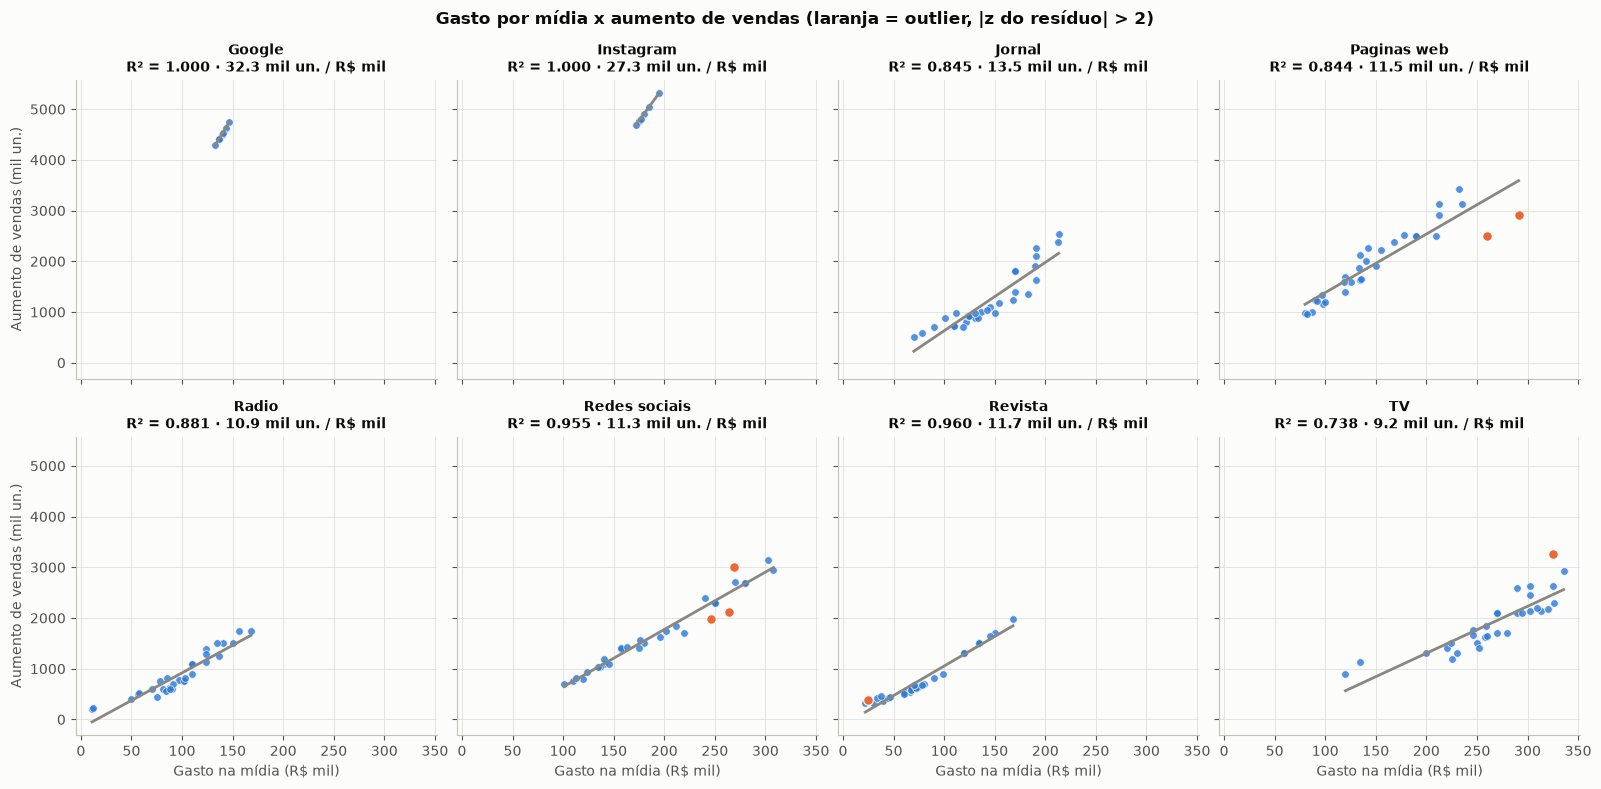

,ano,mes,midia,gasto,vendas,residuo,z
66,2022,12,Paginas web,"260,000.0000","2,500.0000",-729.5000,-2.6100
138,2023,12,Paginas web,"291,200.0000","2,916.0000",-673.6000,-2.4100
97,2023,5,Redes sociais,"246,400.0000","1,983.0000",-314.9000,-2.0300
133,2023,11,Redes sociais,"268,800.0000","3,011.0000",459.6000,2.9600
179,2024,5,Redes sociais,"263,648.0000","2,122.0000",-371.1000,-2.3900
118,2023,8,Revista,"24,640.0000",373.0000,198.7000,2.0500
140,2023,12,TV,"324,800.0000","3,261.0000",802.5000,2.8200


In [13]:
# 6.2 Gasto em cada mídia x vendas (pequenos múltiplos, mesma escala) com reta ajustada e outliers (resíduo padronizado |z| > 2)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
outliers = []
for ax, midia in zip(axes.flat, MIDIAS):
    g = df[df['midia'] == midia]
    lr = LinearRegression().fit(g[['gasto']], g['vendas'])
    res = g['vendas'] - lr.predict(g[['gasto']])
    z = (res - res.mean()) / res.std() if res.std() > 1e-9 else res * 0
    out = z.abs() > 2
    outliers.append(g[out].assign(residuo=res[out].round(1), z=z[out].round(2)))
    ax.scatter(g.loc[~out, 'gasto'] / 1000, g.loc[~out, 'vendas'], s=30, color=AZUL, alpha=0.8, edgecolor='#fcfcfb', linewidth=0.6)
    ax.scatter(g.loc[out, 'gasto'] / 1000, g.loc[out, 'vendas'], s=48, color=LARANJA, edgecolor='#fcfcfb', linewidth=0.8, label='outlier')
    xs = np.linspace(g['gasto'].min(), g['gasto'].max(), 20)
    ax.plot(xs / 1000, lr.predict(pd.DataFrame({'gasto': xs})), color=CINZA, lw=2)
    ax.set_title(f"{midia}\nR² = {lr.score(g[['gasto']], g['vendas']):.3f} · {lr.coef_[0]*1000:.1f} mil un. / R$ mil", fontsize=10)
for ax in axes[-1]: ax.set_xlabel('Gasto na mídia (R$ mil)')
for ax in axes[:, 0]: ax.set_ylabel('Aumento de vendas (mil un.)')
fig.suptitle('Gasto por mídia x aumento de vendas (laranja = outlier, |z do resíduo| > 2)', fontweight='bold')
plt.tight_layout(); plt.show()

tabela_outliers = pd.concat(outliers)[['ano', 'mes', 'midia', 'gasto', 'vendas', 'residuo', 'z']]
tabela_outliers

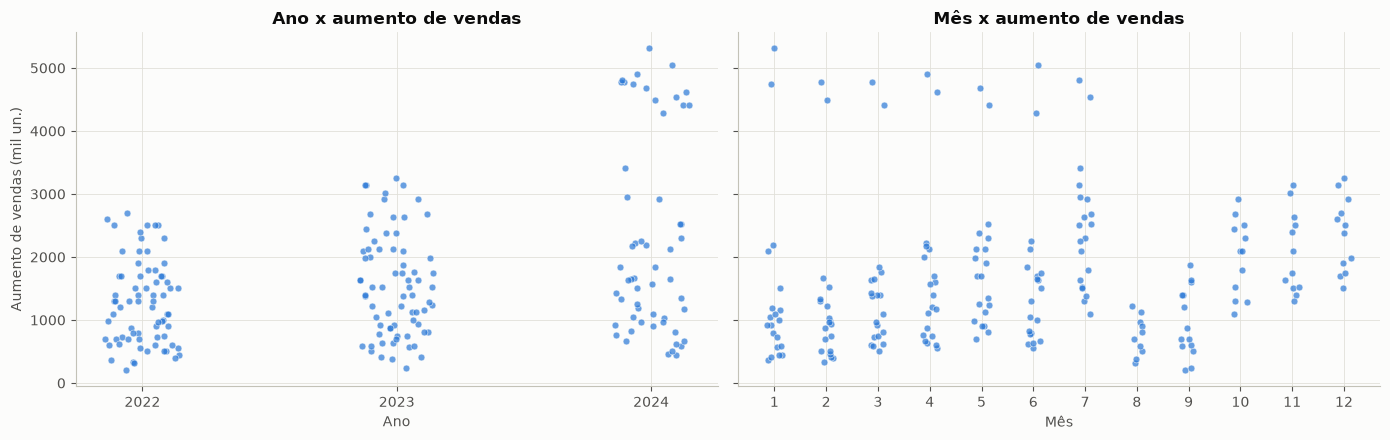

In [14]:
# 6.3 Ano e mês x vendas (variáveis temporais)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
jit = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(df))
axes[0].scatter(df['ano'] + jit, df['vendas'], s=24, color=AZUL, alpha=0.7, edgecolor='#fcfcfb', linewidth=0.5)
axes[0].set_xticks([2022, 2023, 2024]); axes[0].set_title('Ano x aumento de vendas'); axes[0].set_xlabel('Ano')
axes[1].scatter(df['mes'] + jit, df['vendas'], s=24, color=AZUL, alpha=0.7, edgecolor='#fcfcfb', linewidth=0.5)
axes[1].set_xticks(range(1, 13)); axes[1].set_title('Mês x aumento de vendas'); axes[1].set_xlabel('Mês')
axes[0].set_ylabel('Aumento de vendas (mil un.)')
plt.tight_layout(); plt.show()

In [15]:
# 6.4 Evolução do gasto e das vendas por mídia ao longo do tempo (média mensal por ano)
evol = df.groupby(['ano', 'midia'])[['gasto', 'vendas']].mean().round(0).unstack('ano')
evol

gasto                               vendas                      
ano                   2022         2023         2024       2022       2023       2024
midia                                                                                
Google                 NaN          NaN 139,286.0000        NaN        NaN 4,500.0000
Instagram              NaN          NaN 179,614.0000        NaN        NaN 4,899.0000
Jornal        133,417.0000 149,427.0000 151,389.0000 1,078.0000 1,325.0000 1,281.0000
Paginas web   144,400.0000 161,728.0000 148,542.0000 1,762.0000 2,145.0000 2,086.0000
Radio          90,333.0000 101,173.0000 100,875.0000   798.0000   965.0000   894.0000
Redes sociais 183,000.0000 205,160.0000 200,187.0000 1,571.0000 1,872.0000 1,720.0000
Revista        77,333.0000  86,613.0000  78,288.0000   784.0000   917.0000   773.0000
TV            242,917.0000 273,317.0000 293,882.0000 1,658.0000 2,064.0000 2,108.0000

### Comentários — gráficos de dispersão
**Padrões e tendências**
* **Gasto total × vendas (6.1):** a nuvem é dispersa (R² = 0,32). Os pontos de Instagram e Google formam um bloco acima de 4.000 mil unidades com gasto intermediário, e isso "quebra" a reta única.
* **Por mídia (6.2):** todas as mídias têm **tendência linear positiva**, e as inclinações vão de **9,2** (TV) a **32,3** (Google) mil unidades por R$ 1.000. A mesma escala em todos os painéis permite comparar diretamente a inclinação de cada canal.
* **Jornal e Revista** mostram leve curvatura para cima nos maiores orçamentos (o retorno cresce com a escala). Isso motivou o teste do modelo polinomial (M6).
* **TV** tem a maior dispersão (R² = 0,74). Dois meses de orçamento baixo (~R$ 120–135 mil) com vendas relativamente altas achatam a reta.
* **Google e Instagram** têm pontos **perfeitamente alinhados** (R² = 1,000 e razão vendas/gasto constante). Isso sugere que a previsão dessas mídias foi calculada por uma fórmula fixa. Além disso, são só 7 pontos numa faixa estreita de orçamento (R$ 132–195 mil): **extrapolar para orçamentos muito diferentes é arriscado**.

**Outliers (resíduo padronizado |z| > 2): 7 meses**
* **Páginas web dez/2022 e dez/2023:** orçamentos mais altos da mídia (R$ 260–291 mil) com vendas **abaixo** da reta, um sinal de **retorno decrescente** em investimento muito alto.
* **Redes sociais** mai/2023 e mai/2024 ficaram abaixo da reta; nov/2023 ficou acima (+460).
* **TV dez/2023** ficou bem acima da reta (+803), e **Revista ago/2023** também ficou acima.
* Há concentração em **novembro/dezembro**, compatível com sazonalidade de fim de ano (Black Friday/Natal).
* **Decisão:** os outliers foram **mantidos**. São poucos (3,5% das linhas), plausíveis como comportamento de mercado e não são erro de digitação. Removê-los inflaria o R² artificialmente.

**Variáveis temporais (6.3 e 6.4):** 2024 concentra os maiores aumentos por causa de Instagram/Google. Por mês não há padrão claro. Entre 2022 e 2023, o orçamento subiu em todas as mídias e as vendas previstas acompanharam. Em 2024 a TV recebeu mais verba (média de R$ 294 mil/mês) sem aumento proporcional de vendas.

## 7. Modelagem — busca do melhor R²
Comparamos modelos de complexidade crescente. Para evitar conclusões enviesadas por uma única divisão dos dados (são só 200 linhas):
* **Treino/teste estratificado por mídia (80/20)** — mede o desempenho em dados não vistos;
* **Validação cruzada 5-fold** — média do R² em 5 partições, critério principal de escolha;
* Diferença grande entre R² de treino e de teste/CV = sinal de **overfitting**.

In [16]:
y = base['vendas']
dum_sem_ref = dummies.drop(columns=dummies.columns[0])  # evita a armadilha da dummy (colinearidade com o intercepto)
g2 = gastos_midia.pow(2); g2.columns = [c + '²' for c in g2.columns]

MODELOS = {
    'M1 · gasto total': base[['gasto']],
    'M2 · gasto total + dummies': pd.concat([base[['gasto']], dum_sem_ref], axis=1),
    'M3 · gasto por mídia': gastos_midia,
    'M4 · gasto por mídia + dummies': pd.concat([gastos_midia, dum_sem_ref], axis=1),
    'M5 · M4 + ano + mês': pd.concat([gastos_midia, dum_sem_ref, base[['ano', 'mes']]], axis=1),
    'M6 · M5 + gasto² por mídia (polinomial)': pd.concat([gastos_midia, g2 / 1e5, dum_sem_ref, base[['ano', 'mes']]], axis=1),
}

idx_tr, idx_te = train_test_split(base.index, test_size=0.2, random_state=SEED, stratify=df['midia'])
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
linhas = []
for nome, X in MODELOS.items():
    mdl = LinearRegression().fit(X.loc[idx_tr], y.loc[idx_tr])
    pred_te = mdl.predict(X.loc[idx_te])
    cv = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
    linhas.append({'modelo': nome, 'n_variáveis': X.shape[1],
                   'R² treino': mdl.score(X.loc[idx_tr], y.loc[idx_tr]), 'R² teste': r2_score(y.loc[idx_te], pred_te),
                   'R² CV (média)': cv.mean(), 'R² CV (desvio)': cv.std(),
                   'RMSE teste': np.sqrt(mean_squared_error(y.loc[idx_te], pred_te)), 'MAE teste': mean_absolute_error(y.loc[idx_te], pred_te)})
comparacao = pd.DataFrame(linhas).set_index('modelo')
comparacao

,n_variáveis,R² treino,R² teste,R² CV (média),R² CV (desvio),RMSE teste,MAE teste
modelo,,,,,,,
M1 · gasto total,1,0.3471,0.2193,0.3239,0.1036,"1,030.7703",626.6582
M2 · gasto total + dummies,8,0.7721,0.7126,0.7500,0.0824,625.4444,320.9683
M3 · gasto por mídia,8,0.9587,0.9683,0.9538,0.0211,207.7289,158.6778
M4 · gasto por mídia + dummies,15,0.9647,0.9766,0.9597,0.0171,178.2729,133.0515
M5 · M4 + ano + mês,17,0.9701,0.9749,0.9637,0.0157,184.9452,138.6230
M6 · M5 + gasto² por mídia (polinomial),25,0.9752,0.9810,0.9691,0.0136,160.8932,121.7737


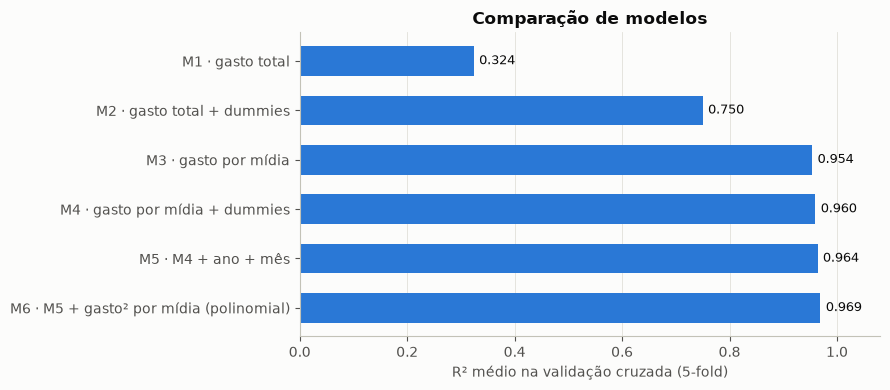

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
ordem = comparacao['R² CV (média)']
ax.barh(ordem.index[::-1], ordem.values[::-1], color=AZUL, height=0.6)
for i, v in enumerate(ordem.values[::-1]):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', color='#0b0b0b', fontsize=9)
ax.set_xlim(0, 1.08); ax.set_xlabel('R² médio na validação cruzada (5-fold)'); ax.set_title('Comparação de modelos')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

### Comentários — comparação de modelos
| Etapa | O que mudou | R² CV |
|---|---|---|
| M1 | só o gasto total | **0,32**: insuficiente, os canais estão misturados |
| M2 | + dummies de mídia | **0,75**: o tipo de mídia explica muito (dica a) |
| M3 | gasto separado por mídia | **0,95**: o maior salto; cada canal tem a própria inclinação (dica b) |
| M4 | M3 + dummies (intercepto por mídia) | **0,96** |
| M5 | M4 + ano e mês | **0,96** |
| M6 | M5 + gasto² por mídia (polinomial) | **0,97**: **maior R²** |

* **Melhor R²:** o **M6** atinge R² de 0,975 no treino, 0,981 no teste e **0,969 na validação cruzada**. A diferença entre treino e CV é pequena (~0,006), então **não há sinal de overfitting**.
* **Ressalva:** o ganho do M6 sobre o M4 é pequeno (+0,009) e custa 10 variáveis a mais, algumas estimadas com apenas 7 pontos (Google/Instagram). Por isso:
  * o **M6** é o modelo de **previsão** (maior R², objetivo do desafio);
  * o **M4** é o modelo de **explicação do ROI**, porque seus coeficientes são diretamente "mil unidades por real investido" em cada mídia.

## 8. Modelo final

In [18]:
NOME_FINAL = comparacao['R² CV (média)'].idxmax()
X_final = MODELOS[NOME_FINAL]
modelo_final = LinearRegression().fit(X_final, y)
pred_cv = cross_val_predict(LinearRegression(), X_final, y, cv=kf)

print('Modelo escolhido:', NOME_FINAL)
print(f'R² (ajuste em toda a base): {modelo_final.score(X_final, y):.4f}')
print(f'R² fora da amostra (CV 5-fold): {r2_score(y, pred_cv):.4f}')
print(f'Erro médio absoluto (CV): {mean_absolute_error(y, pred_cv):.1f} mil unidades')
coefs = pd.Series(modelo_final.coef_, index=X_final.columns)
print(f'Intercepto: {modelo_final.intercept_:.2f}')
coefs.to_frame('coeficiente')

Modelo escolhido: M6 · M5 + gasto² por mídia (polinomial)
R² (ajuste em toda a base): 0.9768
R² fora da amostra (CV 5-fold): 0.9718
Erro médio absoluto (CV): 137.6 mil unidades
Intercepto: -92773.89


,coeficiente
gasto_Google,0.0249
gasto_Instagram,0.0235
gasto_Jornal,0.0017
gasto_Paginas web,0.0149
gasto_Radio,0.0043
gasto_Redes sociais,0.0055
gasto_Revista,0.0058
gasto_TV,0.0030
gasto_Google²,0.0046
gasto_Instagram²,0.0017


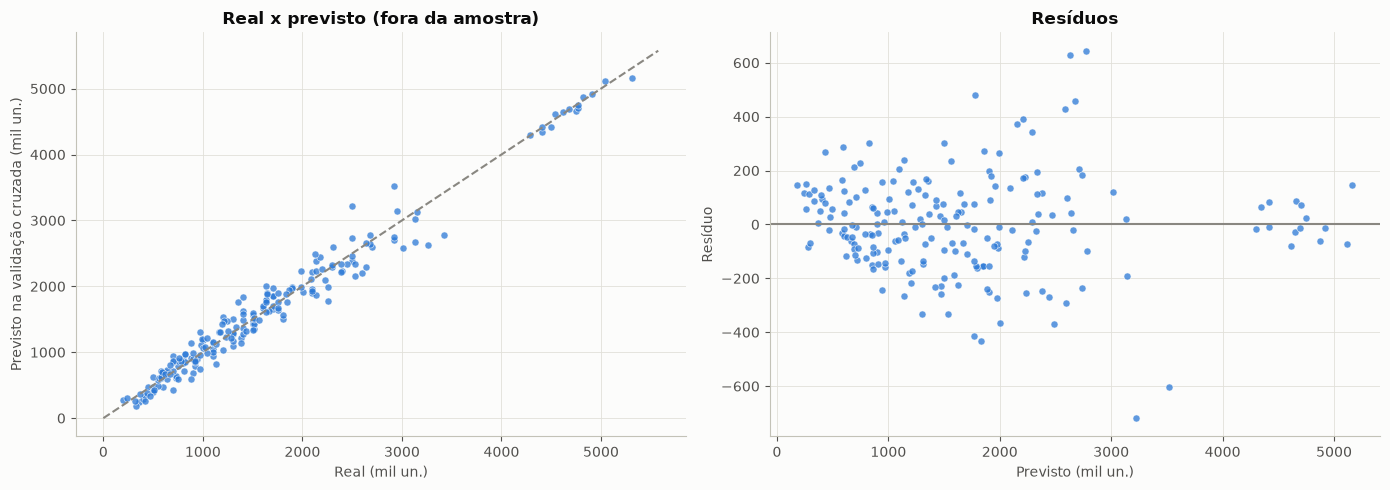

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y, pred_cv, s=26, color=AZUL, alpha=0.75, edgecolor='#fcfcfb', linewidth=0.5)
lim = [0, y.max() * 1.05]
axes[0].plot(lim, lim, color=CINZA, ls='--', lw=1.5)
axes[0].set_xlabel('Real (mil un.)'); axes[0].set_ylabel('Previsto na validação cruzada (mil un.)')
axes[0].set_title('Real x previsto (fora da amostra)')
axes[1].scatter(pred_cv, y - pred_cv, s=26, color=AZUL, alpha=0.75, edgecolor='#fcfcfb', linewidth=0.5)
axes[1].axhline(0, color=CINZA, lw=1.5)
axes[1].set_xlabel('Previsto (mil un.)'); axes[1].set_ylabel('Resíduo'); axes[1].set_title('Resíduos')
plt.tight_layout(); plt.show()

## 9. ROI por mídia
Para uma leitura de negócio usamos o modelo **M4 (gasto por mídia + dummies)**: é o modelo mais simples que dá a cada mídia sua própria reta,
e seu coeficiente `gasto_<mídia>` significa diretamente **quantas mil unidades a mais de vendas cada R$ 1.000 investidos naquela mídia geram** (retorno marginal).
Também mostramos o **retorno médio** observado (vendas ÷ gasto) para comparação.

In [20]:
X4 = MODELOS['M4 · gasto por mídia + dummies']
m4 = LinearRegression().fit(X4, y)
coef4 = pd.Series(m4.coef_, index=X4.columns)

roi = pd.DataFrame({
    'retorno_marginal (mil un. / R$ 1.000)': [coef4[f'gasto_{m}'] * 1000 for m in MIDIAS],
    'retorno_médio (mil un. / R$ 1.000)': [(df.loc[df.midia == m, 'vendas'] / df.loc[df.midia == m, 'gasto']).mean() * 1000 for m in MIDIAS],
    'gasto_médio_mensal (R$)': [df.loc[df.midia == m, 'gasto'].mean() for m in MIDIAS],
    'meses_observados': [int((df.midia == m).sum()) for m in MIDIAS],
}, index=MIDIAS).sort_values('retorno_marginal (mil un. / R$ 1.000)', ascending=False)
roi['índice vs TV'] = roi['retorno_marginal (mil un. / R$ 1.000)'] / roi.loc['TV', 'retorno_marginal (mil un. / R$ 1.000)']
roi

,retorno_marginal (mil un. / R$ 1.000),retorno_médio (mil un. / R$ 1.000),gasto_médio_mensal (R$),meses_observados,índice vs TV
Google,34.3142,32.3077,"139,285.7143",7,4.0309
Instagram,28.8297,27.2727,"179,614.2857",7,3.3866
Jornal,13.6974,8.1861,"143,672.3097",31,1.6090
Revista,11.7092,10.2416,"81,141.1613",31,1.3755
Paginas web,11.6025,13.1104,"152,042.9935",31,1.3629
Redes sociais,11.3898,8.5354,"195,459.0968",31,1.3380
Radio,10.9504,9.4086,"96,909.8839",31,1.2863
TV,8.5128,7.1426,"266,192.7097",31,1.0000


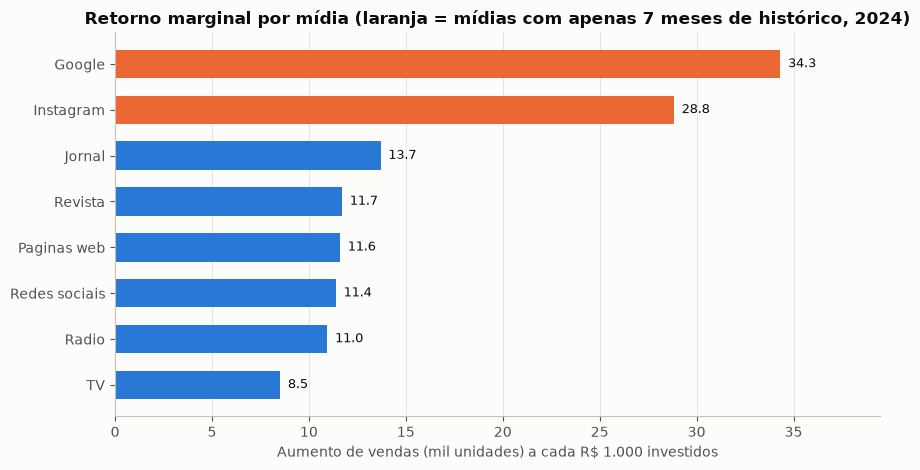

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.8))
s = roi['retorno_marginal (mil un. / R$ 1.000)'].sort_values()
cores = [LARANJA if m in ('Google', 'Instagram') else AZUL for m in s.index]
ax.barh(s.index, s.values, color=cores, height=0.62)
for i, v in enumerate(s.values):
    ax.text(v + 0.4, i, f'{v:.1f}', va='center', fontsize=9, color='#0b0b0b')
ax.set_xlabel('Aumento de vendas (mil unidades) a cada R$ 1.000 investidos')
ax.set_title('Retorno marginal por mídia (laranja = mídias com apenas 7 meses de histórico, 2024)')
ax.grid(axis='y', visible=False); ax.set_xlim(0, s.max() * 1.15)
plt.tight_layout(); plt.show()

In [22]:
# Simulação: previsão de aumento de vendas para R$ 100 mil investidos em cada mídia (modelo M4)
sim = []
for m in MIDIAS:
    linha = pd.DataFrame(0.0, index=[0], columns=X4.columns)
    linha[f'gasto_{m}'] = 100_000
    if f'is_{m}' in linha.columns: linha[f'is_{m}'] = 1.0
    sim.append({'mídia': m, 'vendas previstas com R$ 100 mil (mil un.)': m4.predict(linha)[0]})
pd.DataFrame(sim).set_index('mídia').sort_values('vendas previstas com R$ 100 mil (mil un.)', ascending=False)

,vendas previstas com R$ 100 mil (mil un.)
mídia,
Google,"3,151.6670"
Instagram,"2,602.8537"
Paginas web,"1,378.3813"
Revista,"1,052.8223"
Radio,916.6651
Redes sociais,632.5910
Jornal,618.7953
TV,508.9962


## 10. Análise explicativa para o time de Marketing

### O que fizemos, em linguagem simples
Usamos o histórico de **jan/2022 a jul/2024** (200 registros mensais por mídia) para descobrir **quanto a previsão de vendas aumenta para cada real investido em cada canal**.
O modelo final explica **97% da variação** do aumento de vendas previsto (R² = 0,97 em dados que o modelo não viu). Ou seja, o investimento por canal descreve muito bem o resultado esperado.

### Principais resultados
| Mídia | Retorno médio observado (mil un. por R$ 1.000) | Retorno do modelo (mil un. a cada R$ 1.000 **adicionais**) | Leitura |
|---|---|---|---|
| **Google** | 32,3 | 34,3 | melhor ROI (apenas 7 meses de histórico) |
| **Instagram** | 27,3 | 28,8 | 2º melhor ROI (apenas 7 meses) |
| **Páginas web** | 13,1 | 11,6 | melhor dos canais tradicionais na média |
| **Revista** | 10,2 | 11,7 | eficiente com orçamento pequeno |
| **Rádio** | 9,4 | 11,0 | eficiente com orçamento pequeno |
| **Redes sociais** | 8,5 | 11,4 | intermediário |
| **Jornal** | 8,2 | 13,7 | só compensa com orçamento alto |
| **TV** | 7,1 | 8,5 | **menor ROI** e **maior orçamento** (26% da verba) |

> **Como ler:** "retorno médio" é o que cada canal entregou, em média, por R$ 1.000. "Retorno do modelo" é quanto **cada R$ 1.000 a mais** acrescenta. No Jornal os dois números diferem bastante: o canal precisa de um volume mínimo de investimento para começar a dar resultado.

### Conclusões e recomendações
1. **Google e Instagram trazem o melhor ROI**, cerca de **4 vezes o da TV** por real investido. Com R$ 100 mil, o modelo prevê ~3,2 milhões de unidades a mais no Google e ~2,6 milhões no Instagram, contra ~0,5 milhão na TV.
   **Recomendação:** ampliar a verba desses canais **de forma gradual e medida**. O histórico tem só 7 meses, numa faixa de R$ 132–195 mil/mês, e os pontos perfeitamente alinhados indicam que a previsão veio de uma fórmula fixa. Vale confirmar com as vendas realizadas antes de grandes realocações.
2. **Páginas web** é o canal tradicional mais eficiente e consistente. Porém os meses com orçamento acima de ~R$ 250 mil (dezembros) renderam abaixo do esperado: há sinal de **saturação**.
3. **Revista e Rádio** entregam bom retorno com orçamentos pequenos e funcionam bem como **complemento** da estratégia.
4. **TV** consome a maior fatia da verba (média de R$ 266 mil/mês) e tem o **menor retorno** por real. É a principal candidata a **realocação parcial** para os canais digitais. A TV pode ter valor de marca/alcance que este modelo não mede, então a redução deve ser testada aos poucos.
5. **Redes sociais e Jornal** ficam num patamar intermediário. O Jornal só se paga com investimento alto.

### Cuidados na interpretação
* A variável analisada é a **previsão inicial** de aumento de vendas, e não a venda realizada. O ideal é reaplicar o modelo com as vendas efetivas.
* Regressão mostra **associação**, não prova causa. Recomenda-se validar as mudanças de verba com **testes controlados** (ex.: variar o orçamento de um canal por região ou período).
* O modelo deve ser **reatualizado mensalmente**, sobretudo para Google e Instagram, à medida que o histórico crescer.